# Block-group crosswalk and council-district assignment

Visitor **homes** in the Cuebiq data are Census block groups from **TIGER2019**, i.e. the **2010** block-group
boundaries. The map, however, draws the **2020** block groups (`src/data/OAK_BG.geo.json`, 354 block groups).
Between 2010 and 2020 some block groups were split or re-drawn, so a plain GEOID join silently loses activity:
only 326 of the map's 354 block groups have a matching 2010 GEOID, and 10 of the 336 "Oakland" home block groups
no longer exist under that code.

This notebook builds the lookup tables the next notebook uses to put every home block group on the map:

1. **2010 -> 2020 crosswalk by population-weighted areal interpolation** (same idea as the geohash -> ADA
   interpolation in the Toronto Arts Council project). Each 2010 block group's activity is split across the
   2020 block groups it overlaps, in proportion to *overlap area x 2020 population density* (assumes residents
   are evenly spread within a 2020 block group).
2. **2020 block group -> council district** area weights, so home activity can be summarised by the district
   a visitor lives in.
3. **Corridor -> council district** assignment (which district a corridor sits in), so we can ask what share of
   visitors come from the corridor's *own* district.

**A note on how the weights are normalised.** Weights are normalised over *all* Alameda County 2020 block
groups (with their populations), not just Oakland's. This matters at the city edge: a 2010 block group
that is mostly in San Leandro but clips Oakland by a sliver should send only a sliver of its activity to Oakland,
not all of it (normalising over Oakland block groups alone would force-allocate 100% of it to the sliver). The
weight table is then restricted to Oakland's 354 block groups, so the weights for a source block group sum to
*at most* 1; the remainder is activity that came from outside Oakland. Source block groups that extend beyond
the Alameda County target polygons (county-line cases, water) are scaled down by the fraction of their area that
is covered.

---

| | |
|---|---|
| **Inputs** | `data/activity/processed/home_geography.csv.gz`, `corridor_lookup.csv` (from `01_`)<br>TIGER2019 California block groups (downloaded once to `data/geo/tiger2019_bg/`)<br>`data/geo/block_groups/Alameda_BG.geojson` (2020 block groups + population)<br>`src/data/OAK_BG.geo.json`, `OAK_council_districts.geo.json`, `OAK_CORRIDORS.geo.json`<br>`data/corridors/corridors2/corridors2_final_original.gpkg` (corridor set 2 as queried) |
| **Outputs** | `data/activity/processed/bg_crosswalk_2010_to_2020.csv.gz`<br>`data/activity/processed/bg_district_weights.csv`<br>`data/activity/processed/corridor_districts.csv` |
| **Run after** | `01_combine_corridor_results.ipynb` |

In [1]:
import urllib.request
import warnings
import zipfile
from pathlib import Path

import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from tqdm.auto import tqdm

warnings.filterwarnings("ignore", message="Unable to import Axes3D")

/home/aniket/.local/lib/python3.10/site-packages/matplotlib/projections/__init__.py:63: UserWarning: Unable to import Axes3D. This may be due to multiple versions of Matplotlib being installed (e.g. as a system package and as a pip package). As a result, the 3D projection is not available.
  warnings.warn("Unable to import Axes3D. This may be due to multiple versions of "


In [2]:
# --- Paths ---
# Repo root = nearest parent folder containing package.json, so this notebook runs from any depth.
ROOT = next(p for p in [Path.cwd().resolve(), *Path.cwd().resolve().parents] if (p / "package.json").exists())
DATA = ROOT / "data"                 # raw + intermediate files
SRC_DATA = ROOT / "src" / "data"     # final outputs consumed directly by the web app
PROCESSED_DIR = DATA / "activity" / "processed"

# --- Inputs ---
TIGER_URL = "https://www2.census.gov/geo/tiger/TIGER2019/BG/tl_2019_06_bg.zip"  # California, 2010-vintage block groups
TIGER_DIR = DATA / "geo" / "tiger2019_bg"
TIGER_SHP = TIGER_DIR / "tl_2019_06_bg.shp"

TARGET_UNIVERSE_GEOJSON = DATA / "geo" / "block_groups" / "Alameda_BG.geojson"  # all Alameda County 2020 BGs + pop_count
OAK_BG_GEOJSON = SRC_DATA / "OAK_BG.geo.json"                    # the 354 Oakland block groups drawn on the map
DISTRICTS_GEOJSON = SRC_DATA / "OAK_council_districts.geo.json"
MAP_CORRIDORS_GEOJSON = SRC_DATA / "OAK_CORRIDORS.geo.json"      # corridor polygons the map draws (set 1 + 9 of set 2)
SET2_CORRIDORS_GPKG = DATA / "corridors" / "corridors2" / "corridors2_final_original.gpkg"  # set 2 as queried (10)

HOME_GEOGRAPHY_CSV = PROCESSED_DIR / "home_geography.csv.gz"
CORRIDOR_LOOKUP_CSV = PROCESSED_DIR / "corridor_lookup.csv"

# --- Outputs ---
CROSSWALK_CSV = PROCESSED_DIR / "bg_crosswalk_2010_to_2020.csv.gz"
BG_DISTRICT_CSV = PROCESSED_DIR / "bg_district_weights.csv"
CORRIDOR_DISTRICT_CSV = PROCESSED_DIR / "corridor_districts.csv"

# --- Parameters ---
WORK_CRS = "EPSG:3310"       # California Albers (metres) for all area maths
MIN_OVERLAP_M2 = 100         # intersection pieces smaller than this are boundary noise, not real overlap
MIN_CORRIDOR_DISTRICT_SHARE = 0.20   # a district counts as one a corridor "touches" if it holds >= 20% of its area

# --- Chart styling (see dataviz skill: fixed categorical order, single-hue sequential) ---
CATEGORICAL_PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#4a3aa7", "#e34948"]
CHART_GRID_COLOR = "#e1e0d9"
CHART_MUTED_TEXT = "#898781"
MAP_BASE = "#eceae3"

In [3]:
def style_axis(ax, grid_axis="y"):
    """Shared cosmetic cleanup: recessive grid, no top/right spines."""
    ax.grid(axis=grid_axis, color=CHART_GRID_COLOR, linewidth=0.6, zorder=0)
    ax.set_axisbelow(True)
    for spine in ("top", "right"):
        ax.spines[spine].set_visible(False)
    ax.tick_params(colors=CHART_MUTED_TEXT)


def clean_map_axis(ax):
    ax.set_axis_off()
    ax.set_aspect("equal")


def ensure_tiger_downloaded():
    """One-off download of the TIGER2019 California block-group shapefile from census.gov."""
    if TIGER_SHP.exists():
        return
    TIGER_DIR.mkdir(parents=True, exist_ok=True)
    zip_path = TIGER_DIR / Path(TIGER_URL).name
    print(f"Downloading {TIGER_URL} ...")
    urllib.request.urlretrieve(TIGER_URL, zip_path)
    with zipfile.ZipFile(zip_path) as zf:
        zf.extractall(TIGER_DIR)

## Load geographies

- **Sources**: the TIGER2019 (2010-vintage) block groups that actually appear as visitor homes in the data
  (`home_geography`, 4,753 block groups across nine Bay counties).
- **Targets**: all 1,134 Alameda County 2020 block groups with population. The 354 Oakland ones are the subset the
  map draws.

In [4]:
ensure_tiger_downloaded()

home_geo = pd.read_csv(HOME_GEOGRAPHY_CSV, dtype={"geoid": str})
home_geo["geoid"] = home_geo["geoid"].str.zfill(12)

src_bg = gpd.read_file(TIGER_SHP)[["GEOID", "geometry"]].rename(columns={"GEOID": "src_geoid"})
src_bg = src_bg[src_bg.src_geoid.isin(home_geo.geoid)].to_crs(WORK_CRS).reset_index(drop=True)
src_bg["src_area"] = src_bg.geometry.area

universe = gpd.read_file(TARGET_UNIVERSE_GEOJSON)[["GEOID", "pop_count", "geometry"]].rename(columns={"GEOID": "tgt_geoid"})
universe = universe.to_crs(WORK_CRS)
universe["tgt_area"] = universe.geometry.area
n_nan_pop = universe.pop_count.isna().sum()
universe["pop_count"] = universe.pop_count.fillna(0)          # parks / unpopulated: zero density
universe["pop_density"] = universe.pop_count / universe.tgt_area

oak_bg = gpd.read_file(OAK_BG_GEOJSON)[["GEOID", "pop_count", "geometry"]].to_crs(WORK_CRS)
oak_ids = set(oak_bg.GEOID)

print(f"{len(src_bg)} source block groups (2010 vintage), {len(home_geo)} in home_geography")
print(f"{len(universe)} target block groups (Alameda County, 2020), {n_nan_pop} with missing population (treated as 0)")
print(f"{len(oak_ids)} Oakland map block groups; all in target universe: {oak_ids <= set(universe.tgt_geoid)}")

4753 source block groups (2010 vintage), 4753 in home_geography
1134 target block groups (Alameda County, 2020), 5 with missing population (treated as 0)
354 Oakland map block groups; all in target universe: True


## How well does a plain GEOID join work?

Before interpolating, quantify what a naive join would lose. Home activity from block groups labelled
`Oakland` in the source data should land on the map's block groups:

In [5]:
oak_home = home_geo[home_geo.home_geography == "Oakland"]
direct = oak_home.geoid.isin(oak_ids)

print(f"{len(oak_home)} home block groups are labelled 'Oakland'; {direct.sum()} have a GEOID on the map, "
      f"{(~direct).sum()} do not (their 2010 code was split/re-drawn in 2020):")
display(oak_home.loc[~direct, ["block_group_id", "geoid", "home_lat", "home_lon"]])
print(f"Map block groups with no 2010 GEOID counterpart: {len(oak_ids - set(home_geo.geoid))} of {len(oak_ids)}")

336 home block groups are labelled 'Oakland'; 326 have a GEOID on the map, 10 do not (their 2010 code was split/re-drawn in 2020):


,block_group_id,geoid,home_lat,home_lon
58,US.CA.001.402800.1,060014028001,37.807440,-122.273910
660,US.CA.001.403400.4,060014034004,37.803113,-122.263831
718,US.CA.001.403400.3,060014034003,37.802648,-122.262660
1428,US.CA.001.403300.1,060014033001,37.793760,-122.266734
1911,US.CA.001.403400.1,060014034001,37.809249,-122.259783
3132,US.CA.001.407800.3,060014078003,37.783908,-122.196364
3478,US.CA.001.409000.4,060014090004,37.711854,-122.217890
3687,US.CA.001.402800.2,060014028002,37.809094,-122.270792
4252,US.CA.001.403300.2,060014033002,37.798320,-122.266823
4260,US.CA.001.403400.2,060014034002,37.802410,-122.265107


Map block groups with no 2010 GEOID counterpart: 28 of 354


## Population-weighted overlay

Intersect every source block group with every target block group. Each piece gets
`weight_raw = overlap_area x target_pop_density`. Within a source, weights are normalised to sum to the
source's *covered fraction* (usually 1.0; below 1 only when part of the source lies outside Alameda County or
off the target polygons).

If every target a source touches has zero population, we fall back to plain area weights rather than dropping
the source.

In [6]:
overlay = gpd.overlay(
    src_bg[["src_geoid", "geometry"]],
    universe[["tgt_geoid", "pop_density", "geometry"]],
    how="intersection",
    keep_geom_type=False,
)
overlay["overlap_area"] = overlay.geometry.area
overlay = overlay[overlay.overlap_area >= MIN_OVERLAP_M2].copy()

overlay["weight_raw"] = overlay.overlap_area * overlay.pop_density
raw_total = overlay.groupby("src_geoid")["weight_raw"].transform("sum")
area_total = overlay.groupby("src_geoid")["overlap_area"].transform("sum")

# zero-population fallback
overlay.loc[raw_total == 0, "weight_raw"] = overlay.loc[raw_total == 0, "overlap_area"]
raw_total = overlay.groupby("src_geoid")["weight_raw"].transform("sum")

src_area_lookup = src_bg.set_index("src_geoid")["src_area"]
covered_fraction = (area_total / overlay.src_geoid.map(src_area_lookup)).clip(upper=1.0)
overlay["weight"] = covered_fraction * overlay.weight_raw / raw_total

print(f"{len(overlay)} (source, target) pieces from {overlay.src_geoid.nunique()} source block groups "
      f"({overlay.src_geoid.nunique() / len(src_bg):.0%} of sources touch Alameda County)")

1505 (source, target) pieces from 1058 source block groups (22% of sources touch Alameda County)


In [7]:
# Restrict to the Oakland targets that the map draws
crosswalk = (
    overlay[overlay.tgt_geoid.isin(oak_ids)][["src_geoid", "tgt_geoid", "weight"]]
    .merge(home_geo[["geoid", "home_geography"]].rename(columns={"geoid": "src_geoid"}), on="src_geoid", how="left")
    .reset_index(drop=True)
)
crosswalk["weight"] = crosswalk["weight"].round(6)

per_source = crosswalk.groupby("src_geoid").agg(
    n_targets=("tgt_geoid", "size"), oakland_weight=("weight", "sum"), label=("home_geography", "first")
)
print(f"{len(crosswalk)} crosswalk rows, {len(per_source)} source block groups reach at least one Oakland block group")
print()
print("Total weight sent to Oakland, by the source block group's own label:")
display(per_source.groupby("label").oakland_weight.describe().round(3))

441 crosswalk rows, 351 source block groups reach at least one Oakland block group

Total weight sent to Oakland, by the source block group's own label:


,count,mean,std,min,25%,50%,75%,max
label,,,,,,,,
Oakland,336.0,1.000,0.002,0.981,1.000,1.000,1.000,1.000
Rest East Bay,15.0,0.017,0.048,0.001,0.001,0.004,0.007,0.189


### Reading the crosswalk

- Source block groups **labelled Oakland** should send essentially all (about 100%) of their activity to Oakland
  block groups.
- Source block groups labelled **Rest East Bay** that appear here only clip Oakland's edge. Their total weight
  should be small, which shows the normalisation over the full county is doing its job.

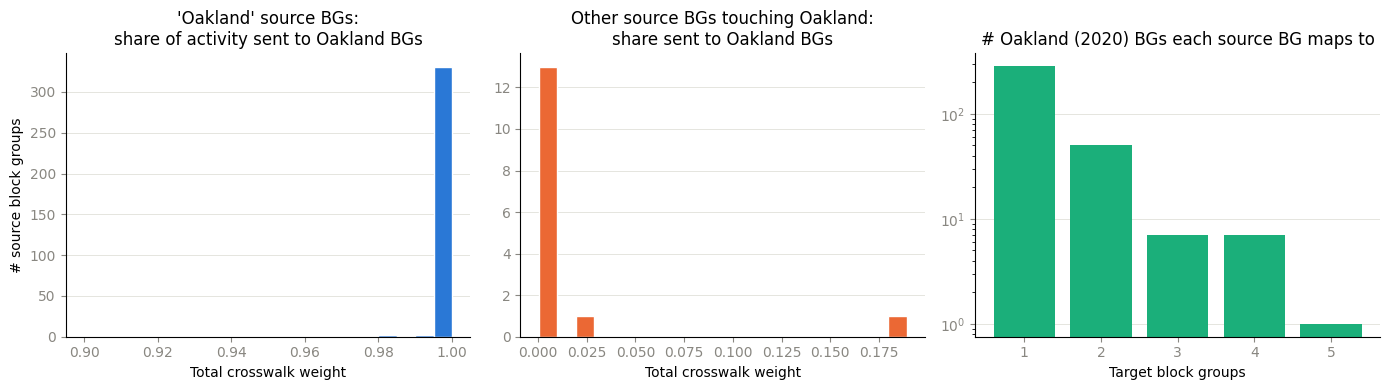

In [8]:
oak_sources = per_source[per_source.label == "Oakland"]
other_sources = per_source[per_source.label != "Oakland"]

fig, axes = plt.subplots(1, 3, figsize=(14, 4))

axes[0].hist(oak_sources.oakland_weight, bins=np.linspace(0.9, 1.0, 21), color=CATEGORICAL_PALETTE[0], edgecolor="white")
axes[0].set_title("'Oakland' source BGs:\nshare of activity sent to Oakland BGs")
axes[0].set_xlabel("Total crosswalk weight")
axes[0].set_ylabel("# source block groups")
style_axis(axes[0])

axes[1].hist(other_sources.oakland_weight, bins=20, color=CATEGORICAL_PALETTE[1], edgecolor="white")
axes[1].set_title("Other source BGs touching Oakland:\nshare sent to Oakland BGs")
axes[1].set_xlabel("Total crosswalk weight")
style_axis(axes[1])

counts = per_source.n_targets.value_counts().sort_index()
axes[2].bar(counts.index, counts.values, color=CATEGORICAL_PALETTE[2])
axes[2].set_title("# Oakland (2020) BGs each source BG maps to")
axes[2].set_xlabel("Target block groups")
axes[2].set_yscale("log")
style_axis(axes[2])

plt.tight_layout()
plt.show()

### The ten re-drawn block groups

These are the source block groups whose 2010 GEOID is not on the map. Each is split across the 2020 block groups
that replaced it:

,n_targets,targets,weights
src_geoid,,,
060014028001,2,"4028022, 4028021","0.78, 0.22"
060014028002,4,"4028011, 4028012, 4028013, 4028021","0.33, 0.33, 0.27, 0.07"
060014033001,4,"4033022, 4033023, 4033021, 4033012","0.40, 0.31, 0.24, 0.06"
060014033002,2,"4033011, 4033012","0.53, 0.47"
060014034001,2,"4034011, 4029001","0.93, 0.07"
060014034002,2,"4034022, 4034021","0.94, 0.06"
060014034003,1,4034013,1.00
060014034004,1,4034012,1.00
060014078003,1,4078001,1.00


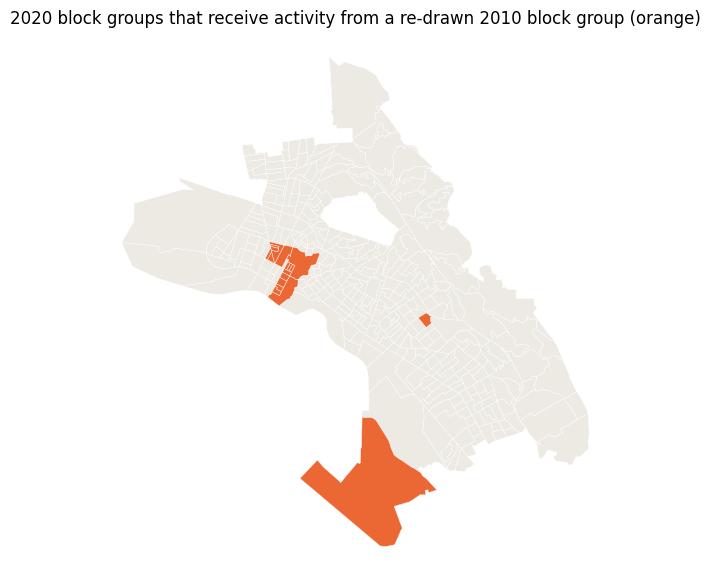

In [9]:
changed = home_geo[(home_geo.home_geography == "Oakland") & ~home_geo.geoid.isin(oak_ids)].geoid
split_detail = (
    crosswalk[crosswalk.src_geoid.isin(changed)]
    .sort_values(["src_geoid", "weight"], ascending=[True, False])
    .assign(weight=lambda d: d.weight.round(3))
)
display(
    split_detail.groupby("src_geoid").agg(
        n_targets=("tgt_geoid", "size"),
        targets=("tgt_geoid", lambda s: ", ".join(s.str[-7:])),
        weights=("weight", lambda s: ", ".join(f"{w:.2f}" for w in s)),
    )
)

fig, ax = plt.subplots(figsize=(7, 7))
oak_bg.plot(ax=ax, color=MAP_BASE, edgecolor="white", linewidth=0.3)
touched = oak_bg[oak_bg.GEOID.isin(split_detail.tgt_geoid)]
touched.plot(ax=ax, color=CATEGORICAL_PALETTE[1], edgecolor="white", linewidth=0.3)
ax.set_title("2020 block groups that receive activity from a re-drawn 2010 block group (orange)")
clean_map_axis(ax)
plt.show()

### Which map block groups get nothing?

Map block groups that no source overlaps with any weight will always render grey. That can happen where nobody
lives (hills, airport, port), since population-weighting sends nothing to zero-population targets unless a
source sits entirely inside one.

In [10]:
received = crosswalk.groupby("tgt_geoid").weight.sum()
oak_bg["received_weight"] = oak_bg.GEOID.map(received).fillna(0)
n_zero = (oak_bg.received_weight == 0).sum()
print(f"{n_zero} of {len(oak_bg)} Oakland block groups receive zero weight; "
      f"{oak_bg.loc[oak_bg.received_weight == 0, 'pop_count'].fillna(0).sum():,.0f} residents live in them")
display(oak_bg.loc[oak_bg.received_weight == 0, ["GEOID", "pop_count"]])

0 of 354 Oakland block groups receive zero weight; 0 residents live in them


,GEOID,pop_count


## Save the crosswalk

In [11]:
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)
crosswalk[["src_geoid", "tgt_geoid", "weight"]].to_csv(CROSSWALK_CSV, index=False)
print(f"Wrote {len(crosswalk)} rows to {CROSSWALK_CSV}")

Wrote 441 rows to /home/aniket/Programming/eddit-east-bay/data/activity/processed/bg_crosswalk_2010_to_2020.csv.gz


## 2020 block group -> council district

Council districts follow block groups closely, but a few block groups straddle a district line. Rather than
assign each to one district, each block group's activity is split by the share of its area in each district
(population density is assumed uniform *inside* a single block group, so area share = population share).

In [12]:
districts = gpd.read_file(DISTRICTS_GEOJSON)[["name", "geometry"]].to_crs(WORK_CRS)
districts["district"] = districts.name.str.extract(r"(\d+)").astype(int)
districts = districts.sort_values("district").reset_index(drop=True)

bg_dist = gpd.overlay(
    oak_bg[["GEOID", "geometry"]], districts[["district", "geometry"]], how="intersection", keep_geom_type=False
)
bg_dist["area"] = bg_dist.geometry.area
bg_area = oak_bg.set_index("GEOID").geometry.area
bg_dist["weight"] = bg_dist.area / bg_dist.GEOID.map(bg_area)
bg_dist = bg_dist[bg_dist.weight > 0.001]                    # ignore boundary slivers

# normalise: block groups are covered ~100% by districts, this just removes sliver rounding
bg_dist["weight"] = bg_dist.weight / bg_dist.groupby("GEOID").weight.transform("sum")
bg_dist = bg_dist.rename(columns={"GEOID": "bg_geoid"})[["bg_geoid", "district", "weight"]]
bg_dist["weight"] = bg_dist.weight.round(5)

n_split = (bg_dist.groupby("bg_geoid").size() > 1).sum()
print(f"{bg_dist.bg_geoid.nunique()} block groups mapped to {bg_dist.district.nunique()} districts; "
      f"{n_split} straddle more than one district")

dominant = bg_dist.sort_values("weight", ascending=False).drop_duplicates("bg_geoid")
print(f"Median share of a block group in its main district: {dominant.weight.median():.3f}")
BG_DISTRICT_CSV.parent.mkdir(parents=True, exist_ok=True)
bg_dist.to_csv(BG_DISTRICT_CSV, index=False)

bg_pop = oak_bg.set_index("GEOID").pop_count.fillna(0)
pop_by_district = (bg_dist.assign(pop=lambda d: d.bg_geoid.map(bg_pop) * d.weight).groupby("district")["pop"].sum())
display(pop_by_district.round(0).astype(int).rename("population (2020 ACS)").to_frame())

354 block groups mapped to 7 districts; 41 straddle more than one district
Median share of a block group in its main district: 1.000


,population (2020 ACS)
district,
1,66324
2,63482
3,66193
4,58610
5,58361
6,60974
7,65474


## Corridor -> council district

Corridors are small, so most sit in one district, but a few straddle a boundary. For each corridor we compute
its area share in each district, define its **primary district** as the one with the most area, and note any
other district holding at least 20% of it. (The corridor polygons used for the Cuebiq query are the same ones the
map draws, except Hegenberger, which was queried but has no polygon in the map's GeoJSON yet, so its geometry
comes from the query's GeoPackage.)

In [13]:
lookup = pd.read_csv(CORRIDOR_LOOKUP_CSV)

# set 1 polygons: the map's GeoJSON; set 2: the GeoPackage the query used (has Hegenberger)
map_corr = gpd.read_file(MAP_CORRIDORS_GEOJSON).to_crs(WORK_CRS)
map_corr["raw_map_name"] = map_corr.corridor_name
map_corr["corridor_name"] = map_corr.corridor_name.str.replace("\xa0", " ").str.strip()

set1 = lookup[lookup.corridor_set == 1].merge(map_corr[["corridor_name", "raw_map_name", "geometry"]], on="corridor_name", how="left")
set2_gpkg = gpd.read_file(SET2_CORRIDORS_GPKG).to_crs(WORK_CRS)[["corridor_id", "geometry"]]
set2 = lookup[lookup.corridor_set == 2].merge(set2_gpkg, on="corridor_id", how="left")
set2 = set2.merge(map_corr[["corridor_name", "raw_map_name"]], on="corridor_name", how="left")

corridors = gpd.GeoDataFrame(pd.concat([set1, set2], ignore_index=True), geometry="geometry", crs=WORK_CRS)
assert corridors.geometry.notna().all(), "a corridor has no polygon"
corridors["area_m2"] = corridors.geometry.area
corridors["in_map"] = corridors.raw_map_name.notna()

print(f"{len(corridors)} corridors with geometry; {corridors.in_map.sum()} are drawn on the map, "
      f"missing from the map: {corridors.loc[~corridors.in_map, 'corridor_name'].tolist()}")

21 corridors with geometry; 20 are drawn on the map, missing from the map: ['Hegenberger']


In [14]:
# Sanity: where both exist, the map polygon and the queried polygon should be (nearly) the same shape
chk = map_corr.set_index("corridor_name").geometry
rows = []
for _, r in corridors[corridors.corridor_set == 2].iterrows():
    if r.corridor_name in chk.index:
        inter = r.geometry.intersection(chk[r.corridor_name]).area
        union = r.geometry.union(chk[r.corridor_name]).area
        rows.append({"corridor": r.corridor_name, "iou_vs_map_polygon": round(inter / union, 3)})
pd.DataFrame(rows)

,corridor,iou_vs_map_polygon
0,Old Oakland,1.0
1,Little Saigon,1.0
2,Dimond,1.0
3,Havencourt,1.0
4,Elmhurst,1.0
5,Uptown Arts & Entertainment District,1.0
6,Northlake,1.0
7,BAMBD,1.0
8,7th St Thrives,1.0


In [15]:
cd = gpd.overlay(corridors[["corridor_slug", "geometry"]], districts[["district", "geometry"]], how="intersection", keep_geom_type=False)
cd["area"] = cd.geometry.area
cd["share"] = cd.area / cd.corridor_slug.map(corridors.set_index("corridor_slug").area_m2)

cd_wide = cd.pivot_table(index="corridor_slug", columns="district", values="share", fill_value=0.0)
cd_wide = cd_wide.reindex(index=corridors.corridor_slug, columns=sorted(districts.district), fill_value=0.0)

corridor_districts = corridors[["corridor_slug", "corridor_name", "corridor_set", "in_map", "area_m2"]].copy()
corridor_districts["raw_map_name"] = corridors.raw_map_name.values
corridor_districts["primary_district"] = cd_wide.idxmax(axis=1).values
corridor_districts["primary_district_share"] = cd_wide.max(axis=1).round(4).values
corridor_districts["touched_districts"] = [
    ",".join(str(d) for d in cd_wide.columns[(cd_wide.loc[s] >= MIN_CORRIDOR_DISTRICT_SHARE).values])
    for s in corridors.corridor_slug
]
for d in cd_wide.columns:
    corridor_districts[f"share_d{d}"] = cd_wide[d].round(4).values
corridor_districts["area_hectares"] = (corridor_districts.area_m2 / 1e4).round(2)
corridor_districts = corridor_districts.drop(columns="area_m2")

corridor_districts.to_csv(CORRIDOR_DISTRICT_CSV, index=False)
corridor_districts[["corridor_slug", "corridor_set", "in_map", "area_hectares", "primary_district", "primary_district_share", "touched_districts"]]

,corridor_slug,corridor_set,in_map,area_hectares,primary_district,primary_district_share,touched_districts
0,downtown,1,True,41.74,3,0.7756,"2,3"
1,chinatown,1,True,61.55,2,0.9961,2
2,lake_merritt,1,True,57.54,3,1.0000,3
3,koreatown_northgate,1,True,35.74,3,1.0000,3
4,montclair,1,True,4.56,4,1.0000,4
5,rockridge,1,True,13.30,1,0.9977,1
6,temescal_telegraph,1,True,49.16,1,0.9871,1
7,fruitvale,1,True,38.73,5,1.0000,5
8,lakeshore,1,True,4.67,2,1.0000,2
9,jack_london,1,True,84.59,3,0.9589,3


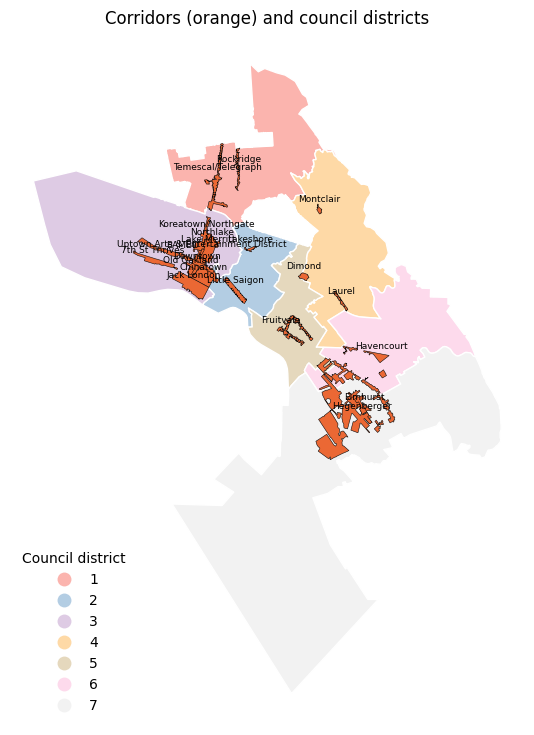

In [16]:
fig, ax = plt.subplots(figsize=(9, 9))
districts.plot(ax=ax, column="district", cmap="Pastel1", edgecolor="white", linewidth=1, categorical=True, legend=True,
               legend_kwds={"title": "Council district", "frameon": False, "loc": "lower left"})
corridors.plot(ax=ax, color=CATEGORICAL_PALETTE[1], edgecolor="#0b0b0b", linewidth=0.4)
for _, r in corridors.iterrows():
    pt = r.geometry.representative_point()
    ax.annotate(r.corridor_name, (pt.x, pt.y), fontsize=6.5, ha="center", va="bottom", xytext=(0, 4), textcoords="offset points")
ax.set_title("Corridors (orange) and council districts")
clean_map_axis(ax)
plt.show()

## Summary of outputs

| File | Rows | Use |
|---|---|---|
| `bg_crosswalk_2010_to_2020.csv.gz` | one per (2010 source BG, Oakland 2020 BG) pair | `03_` splits home activity onto map block groups |
| `bg_district_weights.csv` | one per (Oakland BG, district) pair | `03_` rolls block-group activity up to origin district |
| `corridor_districts.csv` | one per corridor | `03_`/`05_` define "origin in the corridor's own district"; also flags the corridor missing from the map |